<img src="https://www.unad.edu.co/images/footer/logo-unad-acreditacion-min.png" width="780" height="140" align="right"/>

<p style="text-align: center;"> Course: Natural Language Processing</p>

<p style="text-align: center;"> Group: 02 </p>

<p style="text-align: center;"> Phase 3 - Sentiment Analysis and Information Retrieval</p>

<p style="text-align: center;">  Presented by: Jeronimo Ramos Ruiz </p>

<p style="text-align: center;">  Tutor: ANDRES FELIPE HERNANDEZ GIRALDO</p>

<p style="text-align: center;"> UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA - UNAD </p>

<p style="text-align: center;"> Medellín, October 2026</p>

---

# Sentiment Analysis for Mental Health — Lexicons, Semi-Supervised Labeling and Supervised Classification

Corpus: **Sentiment Analysis for Mental Health** (Kaggle, `Combined Data.csv`, referred to here as `mental_health.csv`).
Each row is a *statement* (a social-media post / short text) plus a *status* label
(Normal, Depression, Suicidal, Anxiety, Stress, Bipolar, Personality disorder).

| Stage | Content |
|---|---|
| 1 | Unsupervised, lexicon-based sentiment (VADER, plus a domain-adapted VADER and TextBlob for comparison) |
| 2 | Semi-supervised labeling: small labeled pool → propagate labels to the rest → validate on a gold test set |
| 3 | Supervised classifiers on the (propagated) corpus + metrics + interpretability (feature importance and LIME) |


## 0. Setup

In [19]:
import importlib
import subprocess
import sys

librerias_proyecto = {"numpy": "numpy",
             "pandas": "pandas",
             "matplotlib":"matplotlib",
             "seaborn":"seaborn",
             "openpyxl": "openpyxl",
             "nltk": "nltk",
             "requests": "requests",
             "contractions": "contractions",
             "vaderSentiment": "vaderSentiment",
             "textblob": "textblob",
             "lime":"lime"
             }
             
print("====== INICIANDO VERIFICACIÓN DE ENTORNO ======\n")

# 2. Recorrer y validar cada librería de la lista
for nombre_importar, nombre_pip in librerias_proyecto.items():
    instalada = False
    
    while not instalada:
        try:
            # Intenta cargar la librería dinámicamente
            modulo = importlib.import_module(nombre_importar)
            instalada = True
            
            # Obtener la versión de forma segura
            version = getattr(modulo, "__version__", "Versión no expuesta")
            print(f"[{nombre_importar}] Lista para usar. Versión: {version}")
            
        except ImportError:
            print(f"[{nombre_importar}] No encontrada. Instalando vía pip: '{nombre_pip}'...")
            try:
                # Instala usando el entorno de Python que está ejecutando el script
                subprocess.check_call([sys.executable, "-m", "pip", "install", nombre_pip])
                print(f"[{nombre_importar}] Instalación enviada. Validando acceso...")
            except subprocess.CalledProcessError:
                print(f"[ERROR CRÍTICO] Falló la instalación de '{nombre_pip}'.")
                print("Revisa tu conexión a internet o los permisos de administrador.\n")
                break  # Rompe el ciclo while de esta librería para pasar a la siguiente

print("\n====== PROCESO DE CONFIGURACIÓN FINALIZADO ======")

====== INICIANDO VERIFICACIÓN DE ENTORNO ======

[numpy] Lista para usar. Versión: 2.4.4
[pandas] Lista para usar. Versión: 3.0.2
[matplotlib] Lista para usar. Versión: 3.10.8
[seaborn] Lista para usar. Versión: 0.13.2
[openpyxl] Lista para usar. Versión: 3.1.5
[nltk] Lista para usar. Versión: 3.9.4
[requests] Lista para usar. Versión: 2.33.1
[contractions] Lista para usar. Versión: Versión no expuesta
[vaderSentiment] Lista para usar. Versión: Versión no expuesta
[textblob] Lista para usar. Versión: Versión no expuesta
[lime] No encontrada. Instalando vía pip: 'lime'...
[lime] Instalación enviada. Validando acceso...
[lime] Lista para usar. Versión: Versión no expuesta

====== PROCESO DE CONFIGURACIÓN FINALIZADO ======


In [21]:
# pip install pandas numpy scikit-learn matplotlib vaderSentiment textblob lime
import re, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.semi_supervised import LabelSpreading
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.RandomState(RANDOM_STATE)

# 1. We look out for the path where the notebook is saved
actual_folder = Path('.').resolve()

# 2. We go one folder up
upper_folder = actual_folder.parent

DATA_PATH = upper_folder / 'data/Annex 2 - Combined Data.csv'  
TARGET = "status"                  # label used as ground truth in Stages 2-3
N_LABELED_POOL = 3000              # size of the small randomly-selected subset (train + gold test)
GOLD_TEST_FRACTION = 0.30          # share of that subset reserved as the gold-standard test set

## 1. Loading and describing the corpus
Cleaning is deliberately minimal: drop an unnamed index column if present, drop empty statements and exact duplicate
statements (duplicates would otherwise leak between the labeled pool and the "unlabeled" rest).

Raw shape: (53043, 3) | columns: ['Unnamed: 0', 'statement', 'status']
Rows: 53043 raw -> 52681 after dropping empty -> 51073 after dropping duplicate statements

Words per statement:


,count,mean,std,min,25%,50%,75%,max
n_words,51073.0,112.7,164.1,1.0,15.0,61.0,147.0,6300.0


,n,share_%
status,,
Normal,16039,31.4
Depression,15087,29.5
Suicidal,10641,20.8
Anxiety,3617,7.1
Bipolar,2501,4.9
Stress,2293,4.5
Personality disorder,895,1.8


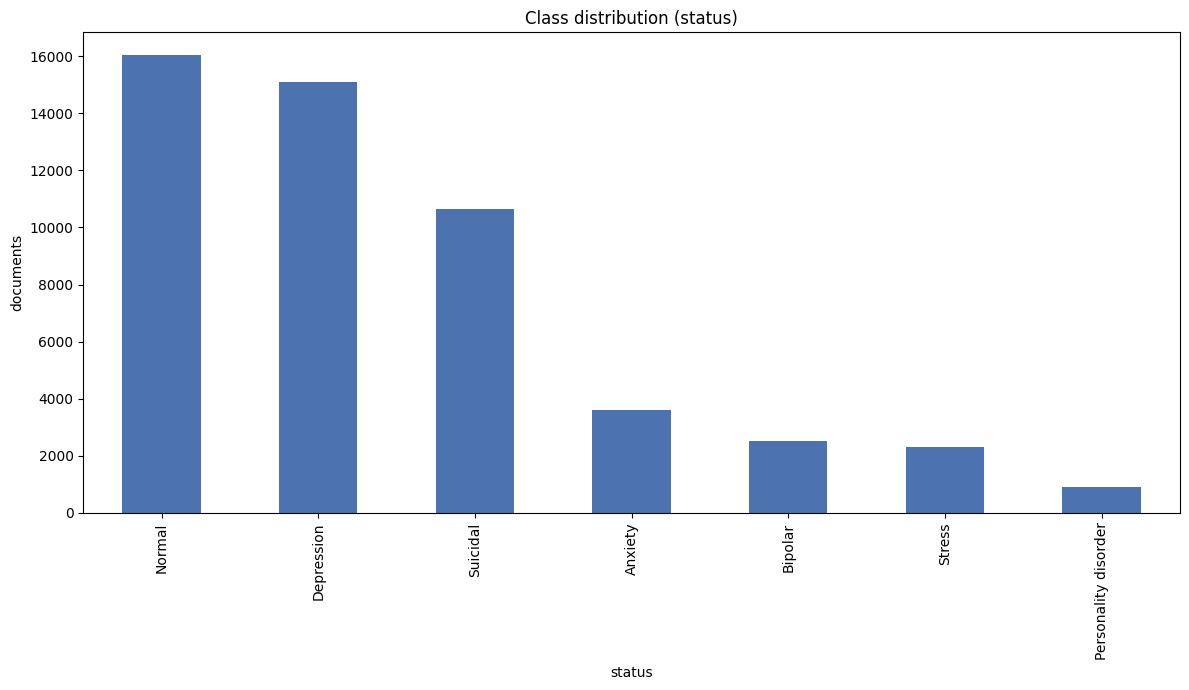

In [6]:
# We start by uploading the data into a variable
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape, "| columns:", list(raw.columns))

# Next, we remove the index or the unnamed column due to the lack of information it provides.
df = raw.loc[:, [c for c in raw.columns if not str(c).lower().startswith("unnamed")]].copy()
df.columns = [c.strip().lower() for c in df.columns]
assert {"statement", "status"} <= set(df.columns), "Expected columns 'statement' and 'status'"

# We start to clean the dataset
n0 = len(df)

# First droping any missing values
df = df.dropna(subset=["statement", "status"])

# Or extra spaces at the end or beginning of the text
df["statement"] = df["statement"].astype(str).str.strip()

# We retain only the rows where the text length is greater than zero.
df = df[df["statement"].str.len() > 0]
n1 = len(df)

# Finally, we retain the unique values ​​for modeling.
df = df.drop_duplicates(subset="statement").reset_index(drop=True)
print(f"Rows: {n0} raw -> {n1} after dropping empty -> {len(df)} after dropping duplicate statements")

df["n_words"] = df["statement"].str.split().str.len()
print("\nWords per statement:"); display(df["n_words"].describe().round(1).to_frame().T)

counts = df["status"].value_counts()
display(pd.DataFrame({"n": counts, "share_%": (100 * counts / len(df)).round(1)}))
ax = counts.plot.bar(figsize=(12, 7), color="#4C72B0", title="Class distribution (status)")
ax.set_ylabel("documents"); plt.tight_layout(); plt.show()

# Stage 1 — Unsupervised, lexicon-based sentiment analysis

### 1.1 Method choice and justification: VADER
**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is the primary method, for these reasons:

* **Language/register fit.** It is built for **English** and tuned on **social-media text**, which matches the Reddit/Twitter-style
  origin of this corpus (informal wording, capitalisation, repeated punctuation, emoticons).
* **Rule-based handling that simpler lexicons lack.** Bing Liu (≈6.8k words) and MPQA are *flat* word lists: they count
  positive vs. negative words but have no intensity values, and no negation/intensifier logic. TextBlob (Pattern) averages
  adjective polarities and has only basic negation handling.
* **No training data needed**, fast, and interpretable (every score can be traced to words).

**How VADER works**
1. **Lexicon:** ≈7,500 tokens (incl. emoticons/slang) each with a mean human-rated valence from −4 (extremely negative) to +4 (extremely positive).
2. **Heuristics adjusting the valence:** *negation* (a negator in the 3 preceding tokens flips and dampens the score, ×−0.74),
   *intensifiers/dampeners* ("very", "extremely", "kind of"), *ALL-CAPS emphasis*, *exclamation/question marks*,
   and *"but"* (sentiment after "but" is up-weighted, before it down-weighted).
3. **Aggregation:** word valences are summed, then normalised to the **compound** score in [−1, +1] with
   `compound = x / sqrt(x² + 15)`; the neg/neu/pos proportions are also returned.
4. **Labels** (standard thresholds): compound ≥ +0.05 → *positive*; ≤ −0.05 → *negative*; otherwise *neutral*.

**Known limitation for this domain.** VADER's lexicon is general-purpose. Distress is often expressed without any
sentiment-bearing word ("I don't see the point anymore"), through sarcasm, or via clinical vocabulary absent from the lexicon.
Section 1.4 therefore also tests a small **domain-adapted** lexicon and compares it with TextBlob.

In [7]:
analyzer = SentimentIntensityAnalyzer()

def vader_scores(texts, sia):
    return pd.DataFrame([sia.polarity_scores(t) for t in texts])

def to_label(compound, thr=0.05):
    return np.where(compound >= thr, "positive", np.where(compound <= -thr, "negative", "neutral"))

vs = vader_scores(df["statement"], analyzer)
df["vader_compound"] = vs["compound"].values
df["vader_label"] = to_label(df["vader_compound"].values)
df[["statement", "status", "vader_compound", "vader_label"]].head(5).assign(
    statement=lambda d: d["statement"].str.slice(0, 90) + "…")

,statement,status,vader_compound,vader_label
0,oh my gosh…,Anxiety,0.0000,neutral
1,"trouble sleeping, confused mind, restless hear...",Anxiety,-0.2263,negative
2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,-0.7351,negative
3,I've shifted my focus to something else but I'...,Anxiety,-0.4215,negative
4,"I'm restless and restless, it's been a month n...",Anxiety,-0.4939,negative


### 1.2 Sentiment distribution

,n,share_%
vader_label,,
negative,28000,54.8
neutral,6282,12.3
positive,16791,32.9


Compound score summary:


,count,mean,std,min,25%,50%,75%,max
vader_compound,51073.0,-0.202,0.668,-1.0,-0.881,-0.273,0.382,1.0


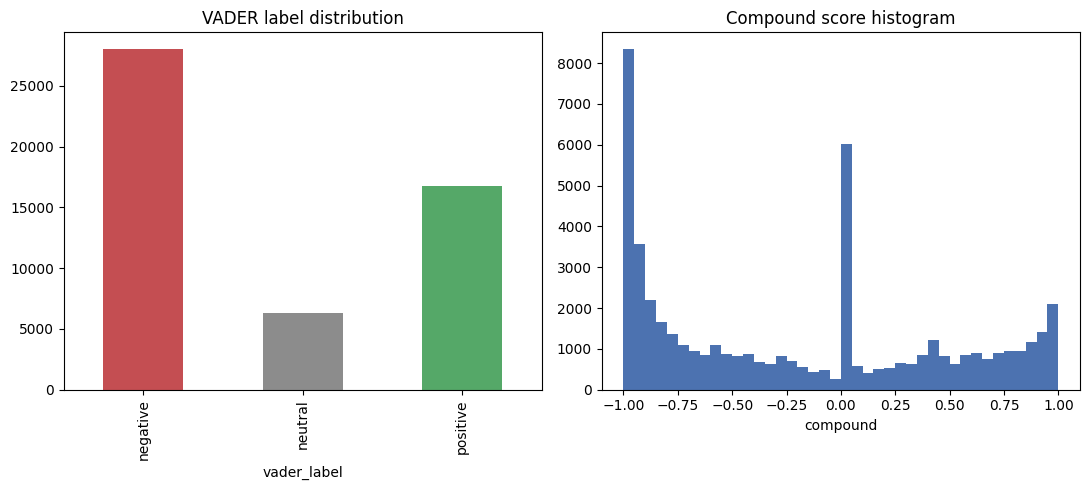

In [8]:
order = ["negative", "neutral", "positive"]
dist = df["vader_label"].value_counts().reindex(order)
display(pd.DataFrame({"n": dist, "share_%": (100 * dist / len(df)).round(1)}))
print("Compound score summary:"); display(df["vader_compound"].describe().round(3).to_frame().T)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
dist.plot.bar(ax=ax[0], color=["#C44E52", "#8C8C8C", "#55A868"], title="VADER label distribution")
ax[1].hist(df["vader_compound"], bins=40, color="#4C72B0"); ax[1].set_title("Compound score histogram")
ax[1].set_xlabel("compound"); plt.tight_layout(); plt.show()

### 1.3 Sentiment vs. mental-health status

vader_label,negative,neutral,positive,mean_compound
status,,,,
Anxiety,71.9,1.8,26.3,-0.363
Bipolar,54.0,2.6,43.4,-0.101
Depression,67.7,2.2,30.1,-0.331
Normal,25.3,33.7,41.0,0.098
Personality disorder,51.6,3.2,45.1,-0.064
Stress,64.2,2.2,33.6,-0.260
Suicidal,73.6,3.1,23.3,-0.442


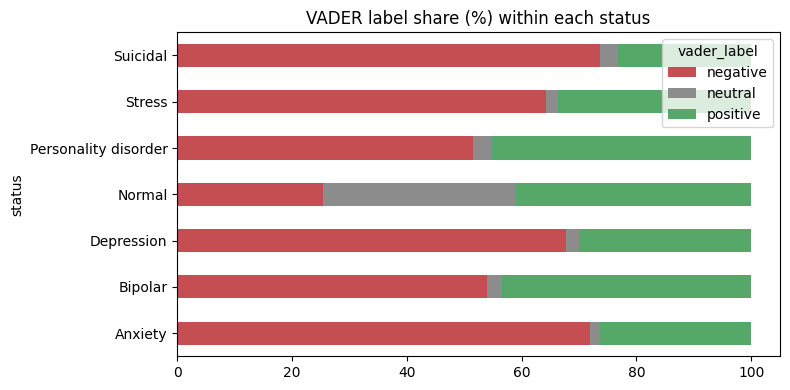

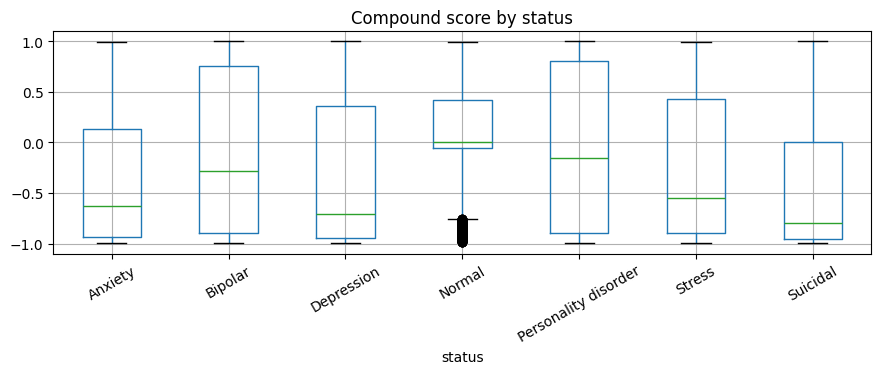

In [9]:
ct = pd.crosstab(df["status"], df["vader_label"], normalize="index").reindex(columns=order).mul(100).round(1)
display(ct.assign(mean_compound=df.groupby("status")["vader_compound"].mean().round(3)))

ct.plot.barh(stacked=True, figsize=(8, 4), color=["#C44E52", "#8C8C8C", "#55A868"],
             title="VADER label share (%) within each status")
plt.tight_layout(); plt.show()

df.boxplot(column="vader_compound", by="status", figsize=(9, 4), rot=30)
plt.suptitle(""); plt.title("Compound score by status"); plt.tight_layout(); plt.show()

### 1.4 Robustness: domain-adapted VADER and a second lexicon (TextBlob)
* **Domain-adapted VADER** — we update VADER's lexicon with a small set of mental-health-related terms. The valences below are
  **hand-set and illustrative** (not validated); the aim is to show how sensitive lexicon scores are to domain vocabulary.
* **TextBlob** polarity in [−1, 1] (same ±0.05 thresholds) is used as an independent lexicon; agreement is measured with Cohen's κ.

> **Interpretation.** VADER labels 54.8 % of the 51,073 statements negative, 12.3 % neutral and 32.9 % positive. Mean compound
> falls monotonically with clinical severity of the label (Suicidal −0.44, Anxiety −0.36, Depression −0.33, Stress −0.26, Bipolar −0.10,
> Personality disorder −0.06, Normal +0.10), so the lexicon captures a real but **coarse** signal. It fails often at the individual level:
> 31.7 % of all non-Normal statements are neutral/positive (about a quarter of Depression, Suicidal and Anxiety posts are labelled *positive*),
> while 25.3 % of Normal statements are labelled negative. Typical causes are implicit distress without sentiment words, narrative or clinical
> vocabulary missing from the lexicon, and positive words used in a negative context. T
he problem is not a few missing words but that polarity is not the same construct as mental-health status.

# Stage 2 — Semi-supervised labeling (emulated)

Although every row has a label, we pretend only a **small random subset** is labeled:

1. Randomly draw a **labeled pool** of `N_LABELED_POOL` documents and *inspect* a sample of it manually.
2. Split the pool into two **disjoint** subsets: a **training** subset (labels used) and a **gold-standard test** subset
   (labels used *only* for evaluation; during propagation they are hidden like the rest of the corpus).
3. Everything outside the pool is the **unlabeled** corpus (its original labels are kept aside and used only for an extra validation).
4. Propagate labels with three methods and a conservative ensemble, then measure accuracy on the gold test set.

### 2.1 Pool selection, manual inspection and train / gold-test split

In [10]:
le = LabelEncoder()
y_all = le.fit_transform(df[TARGET])
classes = list(le.classes_)
n = len(df)

pool_idx = rng.choice(n, size=min(N_LABELED_POOL, n), replace=False)
train_idx, gold_idx = train_test_split(pool_idx, test_size=GOLD_TEST_FRACTION,
                                       stratify=y_all[pool_idx], random_state=RANDOM_STATE)
unl_idx = np.setdiff1d(np.arange(n), pool_idx)

print(f"Labeled pool: {len(pool_idx)}  ->  train: {len(train_idx)} | gold test: {len(gold_idx)} | unlabeled: {len(unl_idx)}")
assert len(set(train_idx) & set(gold_idx)) == 0, "train and gold test must be disjoint"
display(pd.DataFrame({"train": pd.Series(df.loc[train_idx, TARGET]).value_counts(),
                      "gold_test": pd.Series(df.loc[gold_idx, TARGET]).value_counts()}))

# ---- Manual inspection of a random sample of the pool -------------------------------------------
# Read these and decide whether the original label looks right. To *refine* a label, add an entry
# {row_index: "NewLabel"} to MANUAL_OVERRIDES below and re-run from this cell.
MANUAL_OVERRIDES = {}
sample_for_review = rng.choice(pool_idx, size=10, replace=False)
for i in sample_for_review:
    print(f"[row {i}] label = {df.loc[i, TARGET]:<20} | VADER = {df.loc[i, 'vader_label']:<8} | "
          + textwrap.shorten(df.loc[i, 'statement'], 120, placeholder=' […]'))

y_true = y_all.copy()                       # ground truth (original or manually refined)
for i, lab in MANUAL_OVERRIDES.items():
    y_true[i] = le.transform([lab])[0]

Labeled pool: 3000  ->  train: 2100 | gold test: 900 | unlabeled: 48073


,train,gold_test
status,,
Normal,678,291
Depression,602,258
Suicidal,422,180
Anxiety,150,64
Bipolar,109,47
Stress,98,42
Personality disorder,41,18


[row 20348] label = Suicidal             | VADER = negative | Hey there!After a long period of depression and being useless, I pretty much fucked up everything in my life. There […]
[row 44184] label = Normal               | VADER = negative | i suck at french
[row 3955] label = Normal               | VADER = neutral  | Just woke up, give me money
[row 1438] label = Normal               | VADER = positive | Why is my life so much drama like this, I want to laugh but how come it's my life that I laugh at
[row 25458] label = Suicidal             | VADER = positive | There is one last thing id like to do before i die , i want to go alone to the aquarium to look at jellyfish , id do […]
[row 45497] label = Bipolar              | VADER = negative | Changing med times I take quetiapine every night at around 10 pm. I missed a dose last night because silly me forgot […]
[row 40744] label = Depression           | VADER = negative | mizzzidc imagine making sacrifice just to raise a child and sai

### 2.2 Features and hyper-parameter tuning (validation split carved from the *train* subset only)
* TF-IDF fitted on the **texts only** (no labels, so legitimate in a transductive setting). URLs are replaced by a `url` token
  (otherwise `https`/`com` become class "features"). Stop-words are **kept**: negations and first-person pronouns carry signal here.
* **Tuning protocol.** The gold test set is never used for tuning. The train subset is split 70/30 into `tr_in` / `tr_val`;
  we pick the feature set (unigrams vs. unigrams+bigrams) and the regularisation strength `C` / `alpha` by
  **macro-F1 on `tr_val`** (macro-F1 because of the class imbalance). Class weights are 'balanced'.

In [11]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
text_feat = df["statement"].str.replace(URL_RE, " url ", regex=True)

tr_in, tr_val = train_test_split(train_idx, test_size=0.3, stratify=y_true[train_idx], random_state=1)

feature_sets = {"unigrams": dict(ngram_range=(1, 1)), "uni+bigrams": dict(ngram_range=(1, 2))}
tune_rows, mats = [], {}
for fname, kw in feature_sets.items():
    v = TfidfVectorizer(min_df=3, max_df=0.9, max_features=60000, sublinear_tf=True, **kw)
    Xf = v.fit_transform(text_feat); mats[fname] = (v, Xf)
    for C in [0.3, 1, 3, 10]:
        for mname, m in [("LogReg", LogisticRegression(max_iter=2000, C=C, class_weight="balanced")),
                         ("LinearSVC", LinearSVC(C=C, class_weight="balanced", random_state=RANDOM_STATE))]:
            p = m.fit(Xf[tr_in], y_true[tr_in]).predict(Xf[tr_val])
            tune_rows.append({"features": fname, "model": mname, "C": C,
                              "val_f1_macro": f1_score(y_true[tr_val], p, average="macro"),
                              "val_accuracy": accuracy_score(y_true[tr_val], p)})
    for a in [0.1, 0.3, 1.0]:
        p = ComplementNB(alpha=a).fit(Xf[tr_in], y_true[tr_in]).predict(Xf[tr_val])
        tune_rows.append({"features": fname, "model": "ComplementNB", "C": a,
                          "val_f1_macro": f1_score(y_true[tr_val], p, average="macro"),
                          "val_accuracy": accuracy_score(y_true[tr_val], p)})
tune_df = pd.DataFrame(tune_rows).sort_values("val_f1_macro", ascending=False)
display(tune_df.groupby(["model", "features"]).head(1).round(3).reset_index(drop=True))

best_rows = tune_df.groupby("model").head(1).set_index("model")
BEST_FEATURES = tune_df.iloc[0]["features"]
C_LR, C_SVC, ALPHA_NB = (best_rows.loc["LogReg", "C"], best_rows.loc["LinearSVC", "C"], best_rows.loc["ComplementNB", "C"])
print(f"Selected feature set: {BEST_FEATURES} | LogReg C={C_LR} | LinearSVC C={C_SVC} | ComplementNB alpha={ALPHA_NB}")

tfidf, X = mats[BEST_FEATURES]
print("TF-IDF matrix:", X.shape)
svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
X_svd = normalize(svd.fit_transform(X))          # geometry for graph-based label spreading
print("SVD explained variance: %.1f%%" % (100 * svd.explained_variance_ratio_.sum()))

,features,model,C,val_f1_macro,val_accuracy
0,unigrams,LogReg,3.0,0.659,0.729
1,unigrams,LinearSVC,1.0,0.655,0.722
2,uni+bigrams,LogReg,1.0,0.607,0.694
3,uni+bigrams,LinearSVC,0.3,0.587,0.687
4,uni+bigrams,ComplementNB,0.1,0.500,0.587
5,unigrams,ComplementNB,0.1,0.431,0.522


Selected feature set: unigrams | LogReg C=3.0 | LinearSVC C=1.0 | ComplementNB alpha=0.1
TF-IDF matrix: (51073, 20452)
SVD explained variance: 18.0%


### 2.3 Three labelers
* **A1 — Logistic Regression** and **A2 — Linear SVC**, trained on the labeled **train** subset, then applied to all other documents.
* **B — Label Spreading** (graph-based): k-NN graph over the SVD space; labels diffuse from the train subset to *all* other
  documents (gold test labels hidden = −1).

In [12]:
def metrics_row(y, p, name):
    pr_m, rc_m, f1_m, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y, p), "precision_macro": pr_m, "recall_macro": rc_m,
            "f1_macro": f1_m, "f1_micro": f1_score(y, p, average="micro"),
            "f1_weighted": f1_score(y, p, average="weighted")}

# A1 / A2 : supervised on the small labeled train subset
lr_a = LogisticRegression(max_iter=2000, C=C_LR, class_weight="balanced").fit(X[train_idx], y_true[train_idx])
svc_a = LinearSVC(C=C_SVC, class_weight="balanced", random_state=RANDOM_STATE).fit(X[train_idx], y_true[train_idx])
pred_lr, pred_svc = lr_a.predict(X), svc_a.predict(X)

# B : label spreading. Small tuning grid on tr_val (its labels hidden inside the graph), then refit with all train labels.
ls_rows = []
for k, a in [(10, 0.2), (25, 0.2), (25, 0.8)]:
    yh = np.full(n, -1); yh[tr_in] = y_true[tr_in]
    pv = LabelSpreading(kernel="knn", n_neighbors=k, alpha=a, max_iter=30).fit(X_svd, yh).transduction_[tr_val]
    ls_rows.append({"n_neighbors": k, "alpha": a, "val_f1_macro": f1_score(y_true[tr_val], pv, average="macro"),
                    "val_accuracy": accuracy_score(y_true[tr_val], pv)})
ls_df = pd.DataFrame(ls_rows).sort_values("val_f1_macro", ascending=False); display(ls_df.round(3))
K_LS, ALPHA_LS = int(ls_df.iloc[0]["n_neighbors"]), float(ls_df.iloc[0]["alpha"])

y_hidden = np.full(n, -1); y_hidden[train_idx] = y_true[train_idx]
ls = LabelSpreading(kernel="knn", n_neighbors=K_LS, alpha=ALPHA_LS, max_iter=30).fit(X_svd, y_hidden)
pred_ls = ls.transduction_

preds = {"A1 LogReg": pred_lr, "A2 LinearSVC": pred_svc, "B LabelSpreading": pred_ls}
rows = [metrics_row(y_true[gold_idx], p[gold_idx], name) for name, p in preds.items()]
display(pd.DataFrame(rows).set_index("model").round(3))

,n_neighbors,alpha,val_f1_macro,val_accuracy
2,25,0.8,0.469,0.614
1,25,0.2,0.465,0.590
0,10,0.2,0.415,0.551


,accuracy,precision_macro,recall_macro,f1_macro,f1_micro,f1_weighted
model,,,,,,
A1 LogReg,0.730,0.730,0.619,0.655,0.730,0.722
A2 LinearSVC,0.717,0.722,0.603,0.642,0.717,0.706
B LabelSpreading,0.631,0.487,0.448,0.453,0.631,0.620


### 2.4 Method C — conservative corpus by agreement
For every document we take the three predictions and keep the label only if **at least two of the three methods agree**.
Documents without a 2-of-3 majority are discarded from the propagated corpus. We report the **coverage** (share kept) and
the **accuracy on the kept subset**, which is the usual precision/coverage trade-off.

Gold test: coverage = 97.9% | accuracy on kept = 0.740 | macro-F1 on kept = 0.658
Unlabeled corpus: coverage = 97.9% | accuracy of propagated labels vs hidden originals = 0.724


,accuracy,precision_macro,recall_macro,f1_macro,f1_micro,f1_weighted,coverage
model,,,,,,,
A1 LogReg,0.730,0.730,0.619,0.655,0.730,0.722,1.000
A2 LinearSVC,0.717,0.722,0.603,0.642,0.717,0.706,1.000
B LabelSpreading,0.631,0.487,0.448,0.453,0.631,0.620,1.000
C Agreement (kept only),0.740,0.746,0.618,0.658,0.740,0.731,0.979


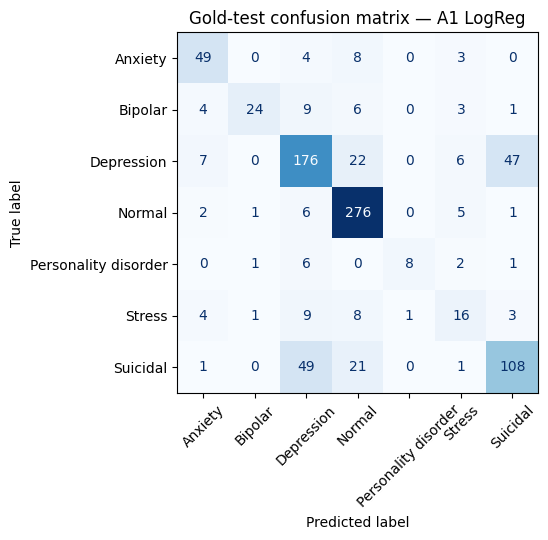

                      precision    recall  f1-score   support

             Anxiety       0.73      0.77      0.75        64
             Bipolar       0.89      0.51      0.65        47
          Depression       0.68      0.68      0.68       258
              Normal       0.81      0.95      0.87       291
Personality disorder       0.89      0.44      0.59        18
              Stress       0.44      0.38      0.41        42
            Suicidal       0.67      0.60      0.63       180

            accuracy                           0.73       900
           macro avg       0.73      0.62      0.66       900
        weighted avg       0.73      0.73      0.72       900



In [13]:
P = np.vstack([pred_lr, pred_svc, pred_ls])           # (3, n)
agree_label = np.full(n, -1)
for i in range(n):
    vals, cnt = np.unique(P[:, i], return_counts=True)
    if cnt.max() >= 2:
        agree_label[i] = vals[cnt.argmax()]
kept = agree_label >= 0

# --- validation on the gold test set (labels never used in propagation) ---
g_kept = gold_idx[kept[gold_idx]]
print(f"Gold test: coverage = {len(g_kept) / len(gold_idx):.1%} | "
      f"accuracy on kept = {accuracy_score(y_true[g_kept], agree_label[g_kept]):.3f} | "
      f"macro-F1 on kept = {f1_score(y_true[g_kept], agree_label[g_kept], average='macro'):.3f}")

# --- extra validation on the 'unlabeled' corpus using its hidden original labels ---
u_kept = unl_idx[kept[unl_idx]]
print(f"Unlabeled corpus: coverage = {len(u_kept) / len(unl_idx):.1%} | "
      f"accuracy of propagated labels vs hidden originals = {accuracy_score(y_all[u_kept], agree_label[u_kept]):.3f}")

summary = pd.DataFrame(rows + [metrics_row(y_true[g_kept], agree_label[g_kept], "C Agreement (kept only)")]).set_index("model")
summary["coverage"] = [1, 1, 1, len(g_kept) / len(gold_idx)]
display(summary.round(3))

best_name = summary.iloc[:3]["f1_macro"].idxmax()
cm = confusion_matrix(y_true[gold_idx], preds[best_name][gold_idx], labels=range(len(classes)))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Gold-test confusion matrix — {best_name}"); plt.tight_layout(); plt.show()
print(classification_report(y_true[gold_idx], preds[best_name][gold_idx], target_names=classes, zero_division=0))

# Stage 3 — Supervised sentiment/status classification

### 3.1 Training corpora
We compare three training sets, always evaluating on the **same gold test subset** (never seen by any labeler or model):

| Corpus | Labels used | Role |
|---|---|---|
| **Propagated** | labeled train subset (true labels) + unlabeled docs kept by the agreement rule (propagated labels) | *the semi-supervised corpus under study* |
| Small-labeled-only | labeled train subset | lower bound |
| Full-original | original labels of every document outside the gold test | upper bound |

### 3.2 Models
Logistic Regression (strong, interpretable linear baseline for sparse text), Linear SVC (the SVC family; linear kernel is the standard choice for TF-IDF)
and Complement Naïve Bayes (fast, designed for imbalanced text classes).

In [14]:
prop_idx = np.concatenate([train_idx, u_kept])
prop_y = np.concatenate([y_true[train_idx], agree_label[u_kept]])
full_idx = np.setdiff1d(np.arange(n), gold_idx)

training_sets = {
    "Propagated corpus": (prop_idx, prop_y),
    "Small labeled only": (train_idx, y_true[train_idx]),
    "Full original labels": (full_idx, y_all[full_idx]),
}
def make_models():
    return {
        "LogReg": LogisticRegression(max_iter=2000, C=3.0, class_weight="balanced"),
        "LinearSVC": LinearSVC(C=0.5, class_weight="balanced", random_state=RANDOM_STATE),
        "ComplementNB": ComplementNB(alpha=0.3),
    }

res, fitted = [], {}
for tname, (idx, yy) in training_sets.items():
    for mname, model in make_models().items():
        model.fit(X[idx], yy)
        p = model.predict(X[gold_idx])
        r = metrics_row(y_true[gold_idx], p, f"{mname} | {tname}"); r["n_train"] = len(idx)
        res.append(r); fitted[(mname, tname)] = (model, p)

results = pd.DataFrame(res).set_index("model")
display(results.round(3))

,accuracy,precision_macro,recall_macro,f1_macro,f1_micro,f1_weighted,n_train
model,,,,,,,
LogReg | Propagated corpus,0.740,0.739,0.656,0.684,0.740,0.735,49141
LinearSVC | Propagated corpus,0.736,0.751,0.649,0.682,0.736,0.729,49141
ComplementNB | Propagated corpus,0.647,0.607,0.526,0.524,0.647,0.638,49141
LogReg | Small labeled only,0.730,0.730,0.619,0.655,0.730,0.722,2100
LinearSVC | Small labeled only,0.727,0.733,0.619,0.657,0.727,0.718,2100
ComplementNB | Small labeled only,0.537,0.449,0.402,0.396,0.537,0.516,2100
LogReg | Full original labels,0.777,0.702,0.759,0.723,0.777,0.778,50173
LinearSVC | Full original labels,0.788,0.734,0.756,0.744,0.788,0.787,50173
ComplementNB | Full original labels,0.670,0.668,0.616,0.618,0.670,0.666,50173


Note: for single-label multiclass problems **micro-averaged F1 equals accuracy**; the macro average (each class weighted equally) is
the honest indicator under class imbalance, and the weighted average reflects the class mix.

Best model on the propagated corpus (macro-F1): LogReg 

                      precision    recall  f1-score   support

             Anxiety       0.73      0.81      0.77        64
             Bipolar       0.84      0.55      0.67        47
          Depression       0.70      0.68      0.69       258
              Normal       0.82      0.94      0.88       291
Personality disorder       0.90      0.50      0.64        18
              Stress       0.51      0.50      0.51        42
            Suicidal       0.66      0.61      0.63       180

            accuracy                           0.74       900
           macro avg       0.74      0.66      0.68       900
        weighted avg       0.74      0.74      0.73       900



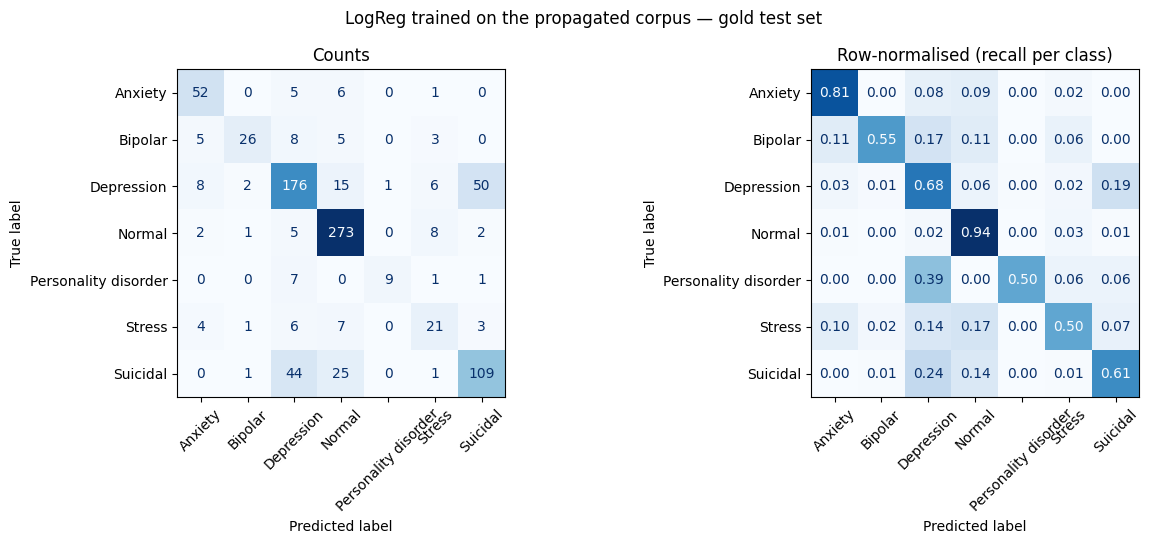

,pred Anxiety,pred Bipolar,pred Depressi,pred Normal,pred Personal,pred Stress,pred Suicidal
true Anxiety,52,0,5,6,0,1,0
true Bipolar,5,26,8,5,0,3,0
true Depression,8,2,176,15,1,6,50
true Normal,2,1,5,273,0,8,2
true Personality disorder,0,0,7,0,9,1,1
true Stress,4,1,6,7,0,21,3
true Suicidal,0,1,44,25,0,1,109


Most frequent confusions (true -> predicted):
            Depression -> Suicidal             50
              Suicidal -> Depression           44
              Suicidal -> Normal               25
            Depression -> Normal               15
               Bipolar -> Depression           8
            Depression -> Anxiety              8

VADER on NON-Normal statuses: negative = 68.3%, neutral/positive = 31.7%
VADER on Normal statements:   negative = 25.3%
Gold test: non-Normal documents the model classifies correctly: 393; of these VADER says positive/neutral for 31.6%


In [15]:
sel = results.loc[[i for i in results.index if i.endswith("Propagated corpus")]]
best_model_name = sel["f1_macro"].idxmax().split(" | ")[0]
model_best, pred_best = fitted[(best_model_name, "Propagated corpus")]
print("Best model on the propagated corpus (macro-F1):", best_model_name, "\n")
print(classification_report(y_true[gold_idx], pred_best, target_names=classes, zero_division=0))

cm = confusion_matrix(y_true[gold_idx], pred_best, labels=range(len(classes)))
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[0], cmap="Blues", xticks_rotation=45, colorbar=False)
ax[0].set_title("Counts")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=classes
                       ).plot(ax=ax[1], cmap="Blues", xticks_rotation=45, colorbar=False, values_format=".2f")
ax[1].set_title("Row-normalised (recall per class)")
plt.suptitle(f"{best_model_name} trained on the propagated corpus — gold test set"); plt.tight_layout(); plt.show()

cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c[:8]}" for c in classes])
display(cm_df)
off = [(classes[i], classes[j], cm[i, j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
print("Most frequent confusions (true -> predicted):")
for t, p_, k in sorted(off, key=lambda x: -x[2])[:6]:
    print(f"  {t:>20} -> {p_:<20} {k}")

# Lexicon sentiment vs. original status over the whole corpus
nonnormal = df["status"] != "Normal"
print(f"\nVADER on NON-Normal statuses: negative = {(df.loc[nonnormal,'vader_label']=='negative').mean():.1%}, "
      f"neutral/positive = {(df.loc[nonnormal,'vader_label']!='negative').mean():.1%}")
print(f"VADER on Normal statements:   negative = {(df.loc[~nonnormal,'vader_label']=='negative').mean():.1%}")
gl = pd.DataFrame({"true": [classes[i] for i in y_true[gold_idx]], "pred": [classes[i] for i in pred_best],
                   "vader": df.loc[gold_idx, "vader_label"].values})
hit = gl[(gl.true != "Normal") & (gl.true == gl.pred)]
print(f"Gold test: non-Normal documents the model classifies correctly: {len(hit)}; of these VADER says "
      f"positive/neutral for {(hit.vader != 'negative').mean():.1%}")

**Uncertainty.** The gold test set has only 900 documents (e.g. a few dozen Personality-disorder or Stress cases), so differences of 1–2 points are within noise.
We bootstrap the gold test set (1,000 resamples) to get 95 % confidence intervals for the three models trained on the propagated corpus.

In [16]:
rngb = np.random.RandomState(0)
yg = y_true[gold_idx]; ci_rows = []
for mname in ["LogReg", "LinearSVC", "ComplementNB"]:
    pg = fitted[(mname, "Propagated corpus")][1]
    accs, f1s = [], []
    for _ in range(1000):
        b = rngb.randint(0, len(yg), len(yg))
        accs.append(accuracy_score(yg[b], pg[b])); f1s.append(f1_score(yg[b], pg[b], average="macro"))
    ci_rows.append({"model": mname, "accuracy": accuracy_score(yg, pg), "acc_95CI": f"[{np.percentile(accs,2.5):.3f}, {np.percentile(accs,97.5):.3f}]",
                    "f1_macro": f1_score(yg, pg, average="macro"), "f1_macro_95CI": f"[{np.percentile(f1s,2.5):.3f}, {np.percentile(f1s,97.5):.3f}]"})
display(pd.DataFrame(ci_rows).set_index("model").round(3))

,accuracy,acc_95CI,f1_macro,f1_macro_95CI
model,,,,
LogReg,0.740,"[0.711, 0.769]",0.684,"[0.635, 0.727]"
LinearSVC,0.736,"[0.707, 0.764]",0.682,"[0.629, 0.727]"
ComplementNB,0.647,"[0.616, 0.679]",0.524,"[0.477, 0.569]"


### 3.3 Interpretability
**Global view — feature importance.** For the linear models the coefficients are directly interpretable: the largest positive
coefficients of a class are the n-grams that push a document towards it.

In [17]:
lr_final = fitted[("LogReg", "Propagated corpus")][0]
feat = np.array(tfidf.get_feature_names_out())
top = {}
for k, c in enumerate(lr_final.classes_):
    top[classes[c]] = feat[np.argsort(lr_final.coef_[k])[::-1][:12]]
display(pd.DataFrame(top))

,Anxiety,Bipolar,Depression,Normal,Personality disorder,Stress,Suicidal
0,anxiety,bipolar,depression,you,avpd,stress,am
1,anxious,meds,wa,wa,avoidant,stressed,die
2,restless,manic,am,oh,poll,and,suicidal
3,worried,mania,depressed,her,people,he,suicide
4,nervous,episode,friend,morning,view,help,not
5,worry,lamictal,not,twitter,social,to,cannot
6,symptoms,seroquel,feel,she,url,url,myself
7,health,ve,feeling,bed,way,don,kill
8,blood,diagnosed,into,play,others,haven,fucking
9,had,for,just,come,talk,our,tired


**Local view — LIME** on three representative gold-test documents: the *most confidently correct* prediction for three
different classes (preferring Normal, Depression and Suicidal, if present). LIME perturbs the text by removing words and fits a
sparse local linear model to show which words push the prediction towards or away from the predicted class.

LIME weights: Yes (+0.00), toyba (-0.00)

=== row 6366 | TRUE = Normal | PREDICTED = Normal | VADER = positive ===
Yes toyba


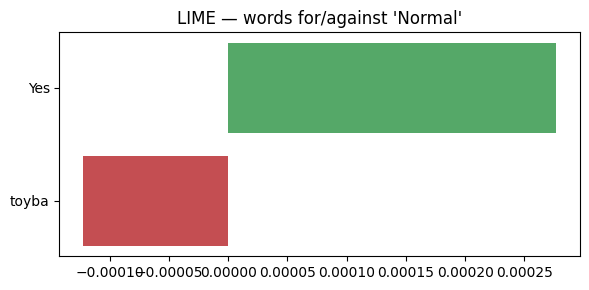

LIME weights: depression (+0.08), wa (+0.07), depressed (+0.05), anxiety (+0.04), my (+0.04), of (+0.03), year (+0.03), bipolar (-0.02), suicide (-0.01), psychiatrist (-0.01)

=== row 39834 | TRUE = Depression | PREDICTED = Depression | VADER = positive ===
i ve been depressed since i wa year old recently got diagnosed with bipolar personality disorder when i already got diagnosed with anorexia binge eating ibs issue anxiety and depression every day […]


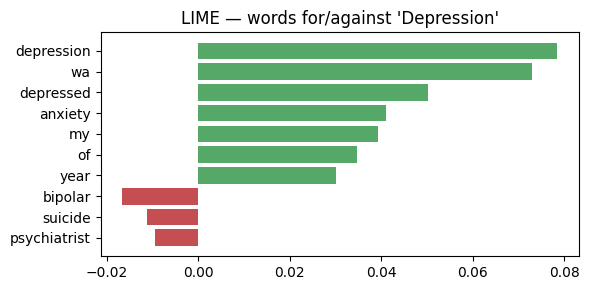

LIME weights: die (+0.06), am (+0.04), to (+0.03), not (+0.03), fucking (+0.03), Death (+0.03), me (+0.02), feeling (-0.01), work (-0.00), lawyer (-0.00)

=== row 7442 | TRUE = Suicidal | PREDICTED = Suicidal | VADER = negative ===
I tried to end it all last night but it did not work. I just woke up today feeling high from all the drugs and alcohol I took . I am probably going to jail next month (1-4 years) for something I […]


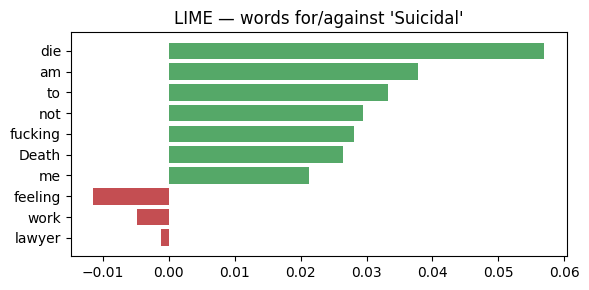

LIME weights: depression (+0.08), depressed (+0.07), suicidal (-0.05), point (+0.03), yet (+0.03), and (+0.03), or (+0.03), life (+0.02), some (+0.02), here (-0.01)

=== row 7635 | TRUE = Suicidal | PREDICTED = Depression | VADER = negative ===
I do not feel depressed yet I have been diagnosed with it I just do not want to live and for some reason mental health professionals think being suicidal means your depressed which I am not I just […]


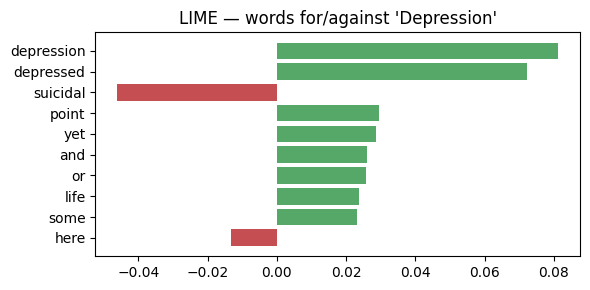

In [22]:
from lime.lime_text import LimeTextExplainer

pipe = make_pipeline(FunctionTransformer(lambda xs: [URL_RE.sub(" url ", t) for t in xs]), tfidf, lr_final)                 # raw text -> probabilities
explainer = LimeTextExplainer(class_names=classes, random_state=RANDOM_STATE)

proba_gold = lr_final.predict_proba(X[gold_idx])
pred_gold = lr_final.classes_[proba_gold.argmax(1)]
wanted = [c for c in ["Normal", "Depression", "Suicidal"] if c in classes]
wanted += [c for c in pd.Series(df.loc[gold_idx, TARGET]).value_counts().index if c not in wanted]
chosen = []
for cname in wanted[:3]:
    ci = le.transform([cname])[0]
    ok = np.where((pred_gold == ci) & (y_true[gold_idx] == ci))[0]
    if len(ok):
        j = ok[np.argmax(proba_gold[ok, list(lr_final.classes_).index(ci)])]
        chosen.append((gold_idx[j], ci))

wrong = np.where(pred_gold != y_true[gold_idx])[0]
if len(wrong):                                        # one confident error, for error analysis
    j = wrong[np.argmax(proba_gold[wrong].max(1))]
    chosen.append((gold_idx[j], int(pred_gold[j])))

for row, ci in chosen:
    text = df.loc[row, "statement"]
    exp = explainer.explain_instance(text, pipe.predict_proba, labels=[ci], num_features=10, num_samples=1500)
    words, weights = zip(*exp.as_list(label=ci))
    print("LIME weights:", ", ".join(f"{w} ({x:+.2f})" for w, x in zip(words, weights)))
    print(f"\n=== row {row} | TRUE = {classes[y_true[row]]} | PREDICTED = {classes[ci]} | VADER = {df.loc[row, 'vader_label']} ===")
    print(textwrap.shorten(text, 200, placeholder=" […]"))
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.barh(words[::-1], weights[::-1], color=["#55A868" if w > 0 else "#C44E52" for w in weights[::-1]])
    ax.set_title(f"LIME — words for/against '{classes[ci]}'"); plt.tight_layout(); plt.show()

### 3.4 Discussion

**Overall performance and cost of semi-supervision.** On the 900-document gold test, logistic regression trained on the propagated corpus reaches
accuracy 0.740 and macro-F1 0.684 (Linear SVC 0.736 / 0.680; Complement NB 0.646 / 0.537). Training on only the 2,100 labeled documents gives 0.730 / 0.655,
and training on the original labels of the whole corpus gives 0.776 / 0.721. Propagation therefore recovers roughly a fifth of the accuracy gap and about
two fifths of the macro-F1 gap, but the bootstrap 95 % intervals (accuracy [0.711, 0.769], macro-F1 [0.635, 0.727]) overlap with the lower bound, so the gain is
suggestive, not statistically established. Label spreading was the weakest labeler (0.631 / 0.453): the 100-d SVD keeps only ~18 % of the TF-IDF variance, so the k-NN graph is
poorly informative, and the 2-of-3 agreement rule (97.9 % coverage) mostly reflects logistic regression and SVC agreeing. A better graph (more components, cosine on TF-IDF directly, or sentence embeddings) is the obvious improvement.

**Where the model fails.** Per-class F1: Normal 0.88, Anxiety 0.77, Depression 0.69, Bipolar 0.67, Personality disorder 0.64 (only 18 test cases), Suicidal 0.63, Stress 0.51.
The two most frequent errors are Depression → Suicidal (50) and Suicidal → Depression (44), about 40 % of all 234 errors: the two classes share vocabulary and differ in degree of intent, which bag-of-words
cannot measure. Suicidal → Normal (25 of 180, 14 %) is the clinically worst error type. Stress is confused with almost everything (recall 0.50), and Personality disorder is mostly absorbed by Depression (7 of 18).

**What drives the decisions (global coefficients + LIME).** The largest coefficients are condition names, medications and symptom words for each class (anxiety/anxious/restless; manic/mania/lamictal/seroquel; die/suicidal/kill/cannot/myself;
avpd/avoidant), while Normal is led by short conversational words. LIME on four gold-test documents confirms the pattern:
* *Depression (correct):* "depression", "depressed", "anxiety", "my" push towards Depression, although the post lists several diagnoses (comorbidity), so the label is only one of several plausible ones.
* *Suicidal (correct):* "die", "am", "not", "death" drive the prediction. First-person pronouns and negations/absolutes in suicidal language match findings in the literature on depression and suicidality, although the weights per word are small (≤0.06) because the evidence is spread over many features.
* *Normal (correct):* the example is a two-word message; every LIME weight is ≈0, i.e. the model defaults to the majority/"chat-like" class when there is no clinical vocabulary, which is why Suicidal → Normal errors occur for implicit or indirect expressions.
* *Error case (true Suicidal, predicted Depression):* the author writes that they do **not** feel depressed but do **not** want to live. "depression"/"depressed" add +0.08/+0.07 towards Depression, and "suicidal" counts against it:
  a bag-of-words model has no notion of negation scope, so it follows the surface vocabulary and misses the meaning.

**Lexicon sentiment vs. the supervised model.** Among the 393 non-Normal gold documents the model classifies correctly, 31.6 % are neutral/positive for VADER, the same share as in the whole corpus (31.7 %).
The classifier recovers distress that the lexicon misses because it learns topic and style cues, not polarity; but it also means that a post's "sentiment" and its clinical status are largely different dimensions.

**Caveats.** (1) Source/topic bias: the classes seem to be partly separated by their origin (explicit condition names and medications, community-specific terms such as "avpd", conversational chat for Normal), so the 74 % accuracy probably overstates generalization to texts from other platforms.
(2) The texts appear to be pre-processed upstream (tokens like "wa" from "was", "ve" from "I've"): "wa" is a high-weight feature, an artefact, not a signal. (3) The gold test is small for the rare classes, hence the wide intervals. (4) Labels are the dataset's original ones; no manual refinement was applied
(`MANUAL_OVERRIDES` is empty). (5) These models are educational and must not be used to screen or make decisions about people.

**Next steps.** Improve the label-spreading graph; try sentence embeddings or a fine-tuned transformer (negation and intent); calibrate and tune thresholds for Stress / Suicidal recall; evaluate on an external mental-health corpus to measure the source-bias effect.